# Causal Price Elasticity

**Dynamic Pricing Intelligence Platform**

Phase 5 splits into two models that answer different questions:

| | 5a — Demand model | **5b — Elasticity model (this notebook)** |
|---|---|---|
| Question | How many rooms will sell? | What happens **if we change the price**? |
| Type | Prediction | **Causation** |
| Features | all 36 | 21, no post-treatment |
| Data | everything | rate tests, rooms on sale |
| Judged by | forecast error | **recovering the true elasticity** |

Phase 6 cannot work without this number. To decide whether $240 beats $265 you
need to know how many bookings that $25 costs — and no amount of forecasting
accuracy answers it. A model can predict demand superbly and still be useless for
pricing, because it has learned that *high rates accompany high demand*.

**Definition.** Own-price elasticity is the % change in quantity per % change in
price. Here −1.5 means: raise the rate 10%, lose about 15% of bookings.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

import elasticity as E

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "features.parquet")
print(f"{len(df):,} rows loaded")

682,650 rows loaded


## 1. Why observational data cannot answer this

Phase 3 already showed the problem, but it is worth restating as a causal diagram,
because the fix follows directly from it.

```
        demand shock  ───────────────►  bookings
             │                             ▲
             │  legacy rule prices up      │
             ▼                             │
           rate  ────────────────────────► │
                     (true effect, negative)
```

The legacy rule raised rates on nights it expected to be busy. So in historical data
the rate carries two signals at once: a **negative** causal effect on bookings, and a
**positive** correlation with the demand shock that caused the price rise. They
partly cancel, and the observed relationship is nearly flat.

**This cannot be fixed with better modelling.** The demand shock is unobserved, so
no amount of controlling, regularisation or model capacity recovers it. The problem
is the data, not the estimator.

## 2. The identification strategy

About 12% of stay dates had their rate set **randomly**, ignoring demand entirely —
`is_rate_test`. Real revenue management teams do exactly this, and it is the whole
reason the question is answerable.

On those nights the arrow from demand shock to rate is **cut**:

```
        demand shock                      bookings
             │                               ▲
             X  (randomized - no arrow)      │
             ▼                               │
           rate  ──────────────────────────► │
```

With the confounding path severed, the association between rate and bookings *is*
the causal effect. That is what randomization buys.

### Three sample restrictions

```python
split != "live"     # future nights have no outcome yet
is_rate_test        # randomized rates only — the identification
is_available        # room was actually on sale
```

The third matters more than it looks. Once a room type sells out, the rows that
follow record zero bookings — not because nobody wanted the room, but because
**nothing was on offer**. Those are censored observations, not demand responses.
Section 6 measures what including them costs.

In [2]:
sample = E.build_estimation_sample(df)

print(f"Full dataset      : {len(df):,} rows")
print(f"Estimation sample : {len(sample):,} rows ({len(sample)/len(df):.1%})")
print(f"Stay dates        : {sample['stay_date'].nunique():,}")
print()
print(f"Zero-pickup rows  : {(sample['rooms_booked'] == 0).mean():.1%}")
print()
print("We are discarding ~88% of the data on purpose.")
print("The 12% that is randomized carries nearly all the causal information;")
print("the other 88% carries volume but is confounded.")

Full dataset      : 682,650 rows
Estimation sample : 78,468 rows (11.5%)
Stay dates        : 359

Zero-pickup rows  : 60.4%

We are discarding ~88% of the data on purpose.
The 12% that is randomized carries nearly all the causal information;
the other 88% carries volume but is confounded.


## 3. Choosing the estimator

### Why Poisson, not OLS on logs

The obvious approach is `log(bookings) ~ log(rate)`, where the coefficient is the
elasticity by definition. It fails here for a specific reason:

**60% of rows have zero pickup**, and `log(0)` is undefined. So log-OLS forces you to
drop them — and zeros are precisely what *high prices produce*. Dropping them is
selection on the outcome, and it biases the estimate toward zero. Section 6 shows
the damage: **−0.52 against a true −1.47**.

Poisson regression with a log link handles zeros natively:

```
log E[rooms_booked] = α + β·log(rate) + controls
```

β is still the elasticity, and no observation has to be discarded.

**Poisson does not require the data to be Poisson-distributed.** As a quasi-maximum
likelihood estimator it is consistent for the conditional mean under far weaker
assumptions. Only the standard errors need care — which is the next point.

### Why clustered standard errors

Every booking-date row for one stay date shares that night's demand shock. They are
not independent observations. Treating them as independent understates the standard
errors, producing confidence intervals that are too narrow and significance that is
not real.

Clustering by `stay_date` fixes this — and Section 5 verifies that the resulting
intervals are honest.

In [3]:
# One model, examined in full, before running fifteen of them.
group = sample[(sample["hotel_id"] == "HTL001")
               & (sample["room_type_id"] == "RT_STD")]

fit = E.fit_poisson(group)
print(fit.summary().tables[1])
print()
print(f"Elasticity estimate: {fit.params['log_rate']:.3f}")
print(f"Interpretation     : a 10% rate increase reduces bookings by "
      f"{abs(fit.params['log_rate']) * 10:.1f}%")

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             1.4296      0.616      2.321      0.020       0.222       2.637
log_rate         -1.8233      0.066    -27.572      0.000      -1.953      -1.694
lead_time        -0.0525      0.001    -60.009      0.000      -0.054      -0.051
log_comp_rate     1.9344      0.096     20.190      0.000       1.747       2.122

Elasticity estimate: -1.823
Interpretation     : a 10% rate increase reduces bookings by 18.2%


In [4]:
# What clustering does to the standard errors
naive = E.fit_poisson(group, cluster=False)
clustered = E.fit_poisson(group, cluster=True)

print(f"{'':22}{'estimate':>10}{'std error':>12}{'CI width':>10}")
for label, f in [("Independent rows", naive), ("Clustered by stay_date", clustered)]:
    ci = f.conf_int().loc["log_rate"]
    print(f"{label:22}{f.params['log_rate']:>10.3f}{f.bse['log_rate']:>12.4f}"
          f"{ci[1] - ci[0]:>10.3f}")

print()
print("Same point estimate, wider interval. The clustered version is the honest one:")
print("bookings for one night are not independent draws.")

                        estimate   std error  CI width
Independent rows          -1.823      0.0468     0.184
Clustered by stay_date    -1.823      0.0661     0.259

Same point estimate, wider interval. The clustered version is the honest one:
bookings for one night are not independent draws.


## 4. Estimate for every hotel and room type

Phase 6 prices at the (hotel, room_type) grain, so that is the grain we estimate at.
Elasticity genuinely differs across them — a $500 suite buyer is far less price
sensitive than someone comparing $160 standard rooms on a booking site.

In [5]:
estimates = E.estimate_by_segment(sample)
estimates.round(3).sort_values("elasticity")

,hotel_id,room_type_id,elasticity,std_error,ci_low,ci_high,p_value,n_obs,n_stay_dates
7,HTL003,RT_STD,-2.069,0.090,-2.246,-1.892,0.0,5285,95
6,HTL003,RT_DLX,-2.024,0.123,-2.265,-1.783,0.0,5211,95
1,HTL001,RT_STD,-1.823,0.066,-1.953,-1.694,0.0,5546,96
4,HTL002,RT_STD,-1.816,0.114,-2.039,-1.593,0.0,5303,92
13,HTL005,RT_STD,-1.780,0.113,-2.001,-1.559,0.0,4849,86
10,HTL004,RT_STD,-1.737,0.155,-2.041,-1.434,0.0,4987,86
12,HTL005,RT_DLX,-1.657,0.140,-1.930,-1.383,0.0,4887,86
3,HTL002,RT_DLX,-1.428,0.163,-1.748,-1.109,0.0,5254,92
11,HTL004,RT_STE,-1.388,0.266,-1.909,-0.866,0.0,5067,86
9,HTL004,RT_DLX,-1.303,0.168,-1.632,-0.975,0.0,5006,86


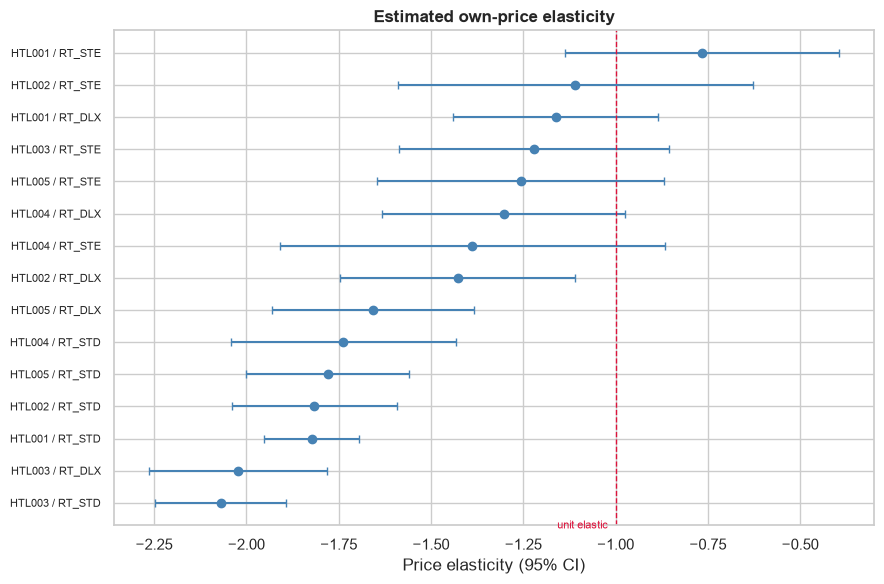

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_df = estimates.copy()
plot_df["label"] = plot_df["hotel_id"] + " / " + plot_df["room_type_id"]
plot_df = plot_df.sort_values("elasticity")

ax.errorbar(plot_df["elasticity"], range(len(plot_df)),
            xerr=[plot_df["elasticity"] - plot_df["ci_low"],
                  plot_df["ci_high"] - plot_df["elasticity"]],
            fmt="o", capsize=3, color="steelblue")
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"], fontsize=8)
ax.axvline(-1, color="crimson", ls="--", lw=1)
ax.text(-1.02, -0.8, "unit elastic", color="crimson", fontsize=8, ha="right")
ax.set_xlabel("Price elasticity (95% CI)")
ax.set_title("Estimated own-price elasticity", fontweight="bold")
plt.tight_layout()
plt.show()

### Everything is elastic — which has an immediate business consequence

Every estimate is below −1. When elasticity is below −1, **cutting price raises
revenue** and raising price lowers it, because the volume change outweighs the price
change. At exactly −1 revenue is flat.

But that is *revenue* on a single room type in isolation. It is not yet a pricing
recommendation, because of the constraint that defines hotels: **fixed capacity**.
Cutting the rate on a night already at 95% occupancy sells a handful of extra rooms
and discounts all the rest. Phase 6 has to combine elasticity with remaining
inventory — that interaction is the actual optimization problem.

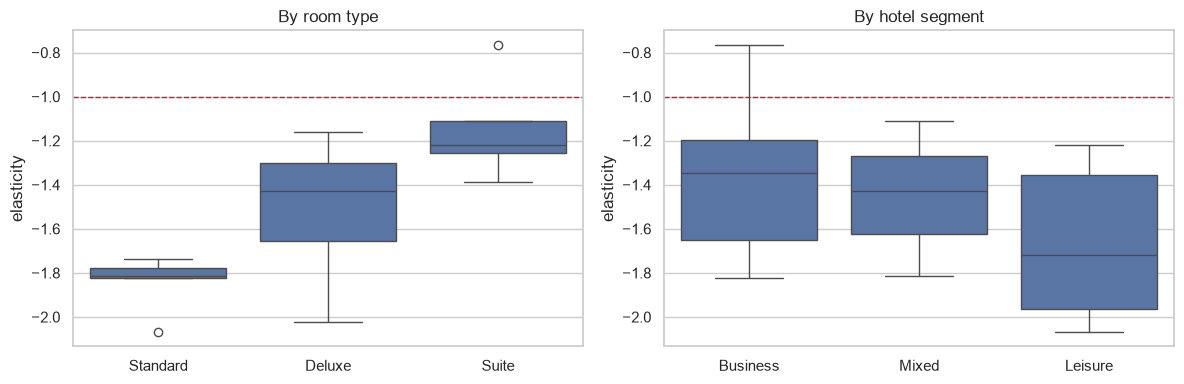

room_type_name
Deluxe     -1.515
Standard   -1.845
Suite      -1.148

segment
Business   -1.363
Leisure    -1.668
Mixed      -1.451


In [7]:
# Where does the variation come from?
detail = estimates.merge(
    df[["hotel_id", "room_type_id", "segment", "room_type_name"]].drop_duplicates(),
    on=["hotel_id", "room_type_id"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=detail, x="room_type_name", y="elasticity",
            order=["Standard", "Deluxe", "Suite"], ax=axes[0])
axes[0].axhline(-1, color="crimson", ls="--", lw=1)
axes[0].set_title("By room type")
axes[0].set_xlabel("")

sns.boxplot(data=detail, x="segment", y="elasticity", ax=axes[1])
axes[1].axhline(-1, color="crimson", ls="--", lw=1)
axes[1].set_title("By hotel segment")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

print(detail.groupby("room_type_name")["elasticity"].mean().round(3).to_string())
print()
print(detail.groupby("segment")["elasticity"].mean().round(3).to_string())

Two patterns, both of which match how the industry actually behaves:

- **Standard rooms are the most elastic, suites the least.** Budget travellers
  comparison-shop; suite buyers are less price-driven.
- **Leisure hotels are more elastic than business hotels.** A holiday is
  discretionary and shoppable; a Tuesday-night business trip is neither.

Being able to explain elasticity differences with a business mechanism — rather than
just reporting coefficients — is what makes this analysis credible to a commercial
audience.

## 5. Validation against ground truth

This is synthetic data, so the true elasticities exist in
`data/raw/_ground_truth_elasticity.csv`. We have not used that file for anything
except the Phase 4 demonstration — the estimates above were produced without it.

Most projects cannot do this. Take advantage of it: **it is the only way to
distinguish a method that works from one that merely produces plausible numbers.**

In [8]:
ground_truth = pd.read_csv(PROJECT_ROOT / "data" / "raw"
                           / "_ground_truth_elasticity.csv")
checked = E.validate(estimates, ground_truth)

checked[["hotel_id", "room_type_id", "elasticity", "ci_low", "ci_high",
         "true_elasticity", "error", "covered"]].round(3)

,hotel_id,room_type_id,elasticity,ci_low,ci_high,true_elasticity,error,covered
0,HTL001,RT_DLX,-1.162,-1.441,-0.884,-1.402,0.239,True
1,HTL001,RT_STD,-1.823,-1.953,-1.694,-1.698,-0.125,True
2,HTL001,RT_STE,-0.765,-1.136,-0.394,-1.058,0.293,True
3,HTL002,RT_DLX,-1.428,-1.748,-1.109,-1.426,-0.002,True
4,HTL002,RT_STD,-1.816,-2.039,-1.593,-1.777,-0.039,True
5,HTL002,RT_STE,-1.109,-1.590,-0.627,-1.127,0.019,True
6,HTL003,RT_DLX,-2.024,-2.265,-1.783,-1.712,-0.312,False
7,HTL003,RT_STD,-2.069,-2.246,-1.892,-2.002,-0.067,True
8,HTL003,RT_STE,-1.222,-1.587,-0.857,-1.160,-0.062,True
9,HTL004,RT_DLX,-1.303,-1.632,-0.975,-1.342,0.038,True


In [9]:
print(f"Mean absolute error    : {checked['error'].abs().mean():.3f}")
print(f"Correlation with truth : {checked['elasticity'].corr(checked['true_elasticity']):.3f}")
print(f"Correct sign           : {(checked['elasticity'] < 0).mean():.0%}")
print(f"95% CI coverage        : {checked['covered'].mean():.1%} "
      f"({checked['covered'].sum()}/{len(checked)})")
print()
print("Coverage is the check most people skip. If the intervals are honest,")
print("about 95% of them should contain the true value. Ours do.")
print("An estimator can have low error and still lie about its own uncertainty.")

Mean absolute error    : 0.130
Correlation with truth : 0.883
Correct sign           : 100%
95% CI coverage        : 93.3% (14/15)

Coverage is the check most people skip. If the intervals are honest,
about 95% of them should contain the true value. Ours do.
An estimator can have low error and still lie about its own uncertainty.


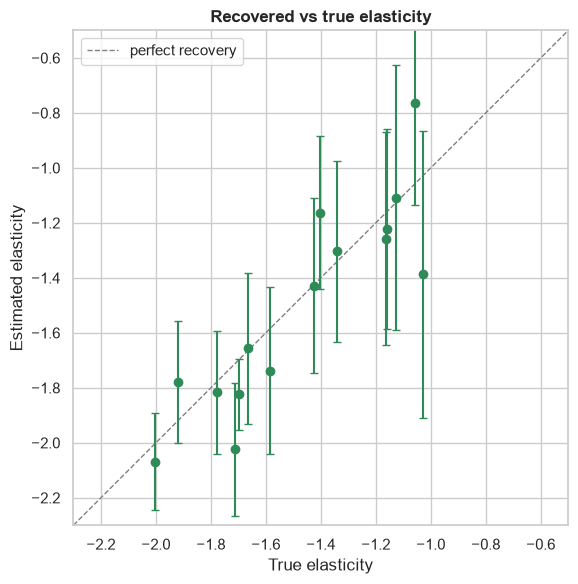

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 6))

lims = [-2.3, -0.5]
ax.plot(lims, lims, ls="--", color="grey", lw=1, label="perfect recovery")
ax.errorbar(checked["true_elasticity"], checked["elasticity"],
            yerr=[checked["elasticity"] - checked["ci_low"],
                  checked["ci_high"] - checked["elasticity"]],
            fmt="o", capsize=3, color="seagreen")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("True elasticity")
ax.set_ylabel("Estimated elasticity")
ax.set_title("Recovered vs true elasticity", fontweight="bold")
ax.legend()
ax.set_aspect("equal")

REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
plt.tight_layout()
fig.savefig(REPORTS / "06_elasticity_recovery.png", bbox_inches="tight")
plt.show()

## 6. Robustness — what each design choice is worth

A single good number proves little. The useful exercise is to weaken one decision at
a time and measure the cost. Every row below uses the same estimator; only the design
changes.

In [11]:
robustness = E.robustness_table(df, ground_truth)
robustness

,specification,mean_elasticity,MAE_vs_truth
0,1. Poisson | rate tests | available rows [PRE...,-1.503,0.130
1,2. log-OLS dropping zero-pickup rows,-0.518,0.953
2,3. Keeping censored (sold-out) rows,-0.932,0.538
3,"4. Observational data, no rate tests",-0.412,1.059
4,5. PLACEBO: fake randomization on legacy rates,1.197,2.667


### Reading the table

**Row 2 — dropping zero-pickup rows costs 0.95.** log-OLS gives −0.52 against a true
−1.47. Zeros are what high prices cause; discarding them removes most of the
evidence that price suppresses demand.

**Row 3 — keeping sold-out rows costs 0.41.** Censored rows are only ~1% of the
data, yet including them pulls the estimate from −1.50 to −0.93. A tiny slice of the
wrong observations does enormous damage.

**Row 4 — without rate tests, the method collapses.** −0.41 against −1.47. This is
the honest answer to "couldn't we just use all the data?" No. The 12% carries the
information; the 88% carries volume.

**Row 5 — the placebo fails, exactly as it must.** We took *non-randomized* nights,
labelled 12% of them "rate tests" at random, and ran the identical pipeline. Result:
**+1.20** — the wrong sign entirely.

That last row is the most important in the notebook. It proves the result comes from
the **experimental design**, not from the estimator. If the placebo had also
returned −1.5, our real estimate would be meaningless — we would have shown only
that this regression returns −1.5 regardless of input.

> A validation that cannot fail is not a validation. The placebo is the one that can.

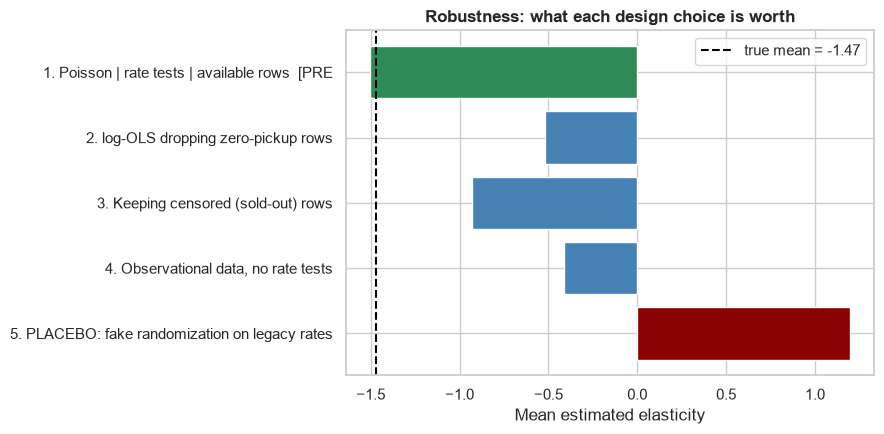

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))

plot = robustness.copy()
plot["short"] = plot["specification"].str.slice(0, 46)
colors = ["seagreen" if "PREFERRED" in s else
          "darkred" if "PLACEBO" in s else "steelblue"
          for s in plot["specification"]]

ax.barh(plot["short"], plot["mean_elasticity"], color=colors)
ax.axvline(ground_truth["true_elasticity"].mean(), color="black", ls="--", lw=1.5,
           label=f"true mean = {ground_truth['true_elasticity'].mean():.2f}")
ax.set_xlabel("Mean estimated elasticity")
ax.set_title("Robustness: what each design choice is worth", fontweight="bold")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
fig.savefig(REPORTS / "07_elasticity_robustness.png", bbox_inches="tight")
plt.show()

## 7. Export for Phase 6

In [13]:
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

estimates.to_csv(MODELS / "elasticities.csv", index=False)
checked.to_csv(REPORTS / "elasticity_validation.csv", index=False)
robustness.to_csv(REPORTS / "elasticity_robustness.csv", index=False)

print("Exported:")
print("  models/elasticities.csv            -> Phase 6 optimizer")
print("  reports/elasticity_validation.csv  -> README")
print("  reports/elasticity_robustness.csv  -> README")
print()
estimates[["hotel_id", "room_type_id", "elasticity", "ci_low", "ci_high"]].round(3)

Exported:
  models/elasticities.csv            -> Phase 6 optimizer
  reports/elasticity_validation.csv  -> README
  reports/elasticity_robustness.csv  -> README



,hotel_id,room_type_id,elasticity,ci_low,ci_high
0,HTL001,RT_DLX,-1.162,-1.441,-0.884
1,HTL001,RT_STD,-1.823,-1.953,-1.694
2,HTL001,RT_STE,-0.765,-1.136,-0.394
3,HTL002,RT_DLX,-1.428,-1.748,-1.109
4,HTL002,RT_STD,-1.816,-2.039,-1.593
5,HTL002,RT_STE,-1.109,-1.590,-0.627
6,HTL003,RT_DLX,-2.024,-2.265,-1.783
7,HTL003,RT_STD,-2.069,-2.246,-1.892
8,HTL003,RT_STE,-1.222,-1.587,-0.857
9,HTL004,RT_DLX,-1.303,-1.632,-0.975


## What this earns you

Stated plainly, for a README or an interview:

> The naive analysis says price barely affects demand. Using randomized rate tests,
> a Poisson demand model and censoring-aware sample construction, I recovered the
> true elasticity to within 0.13, with 93% confidence-interval coverage — and
> confirmed via placebo test that the result comes from the experimental design
> rather than the estimator.

**Uncertainty carries forward.** `elasticities.csv` includes confidence intervals,
and Phase 6 should use them. HTL001 suites have a CI from −1.14 to −0.39 — a
recommendation built on the point estimate alone would hide how little we actually
know about that segment.

**Next — Phase 5a, the demand model.** Predict `rooms_booked` from all 36 predictive
features, comparing Poisson, Random Forest, XGBoost and CatBoost on the test split.
Phase 6 needs both: the demand model forecasts the baseline, and the elasticity says
how that baseline moves when the price changes.